# 02 · Modelado: comparación de regresión logística, Random Forest y boosting

**Objetivo.** Entrenar tres modelos de predicción de abandono, compararlos con validación cruzada usando métricas adecuadas para clases desbalanceadas, elegir el mejor, fijar un umbral de decisión con criterio de negocio y evaluarlo una sola vez sobre el conjunto de test.

**Por qué estos tres modelos.**

| Modelo | Qué es | Por qué incluirlo |
|---|---|---|
| Regresión logística | Modelo lineal: suma ponderada de variables pasada por una sigmoide | Baseline interpretable. Si un modelo complejo no la supera claramente, no vale la complejidad |
| Random Forest | Cientos de árboles entrenados sobre muestras aleatorias, promediados (*bagging*) | Captura no linealidades e interacciones sin ajuste fino; robusto |
| HistGradientBoosting | Árboles secuenciales, cada uno corrige los errores del anterior (*boosting*) | Suele ser el mejor en datos tabulares; versión de scikit-learn, sin dependencias extra |

**Flujo.** Partición estratificada 80/20 → validación cruzada 5-fold sobre el 80% → elección de modelo y umbral → evaluación final sobre el 20%.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

from src.datos import COLUMNA_OBJETIVO, dividir_train_test, separar_predictores_objetivo
from src.evaluacion import (calcular_metricas, elegir_umbral_por_recall, graficar_curvas,
                            graficar_matriz_confusion, resumen_confusion, tabla_costos, tabla_umbrales)
from src.modelos import construir_modelos, probabilidades_cv, validar_modelos

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

OUTPUTS = RAIZ / "outputs"
FIGURAS = OUTPUTS / "figuras"

## 1. Partición train / test

El conjunto de test (20%) se separa **ahora y no se vuelve a tocar** hasta la sección 6. Todas las decisiones intermedias se toman con validación cruzada sobre el train. Si eligiéramos el modelo mirando el test, la métrica final sería optimista.

La partición es **estratificada**: ambos conjuntos conservan el ~16% de abandono.

In [2]:
df = pd.read_csv(RAIZ / "data" / "processed" / "clientes_limpios.csv")
train, test = dividir_train_test(df, proporcion_test=0.2, semilla=42)
X_train, y_train = separar_predictores_objetivo(train)
X_test, y_test = separar_predictores_objetivo(test)

print(f"Train: {len(train):,} clientes  |  abandono = {y_train.mean():.2%}")
print(f"Test : {len(test):,} clientes  |  abandono = {y_test.mean():.2%}")
print(f"Predictores: {X_train.shape[1]}")

Train: 8,101 clientes  |  abandono = 16.07%
Test : 2,026 clientes  |  abandono = 16.04%
Predictores: 19


## 2. Preprocesamiento dentro del pipeline

Cada modelo es un `Pipeline` de dos pasos: `prep` (ColumnTransformer) + `modelo`. Esto garantiza que, en cada fold de la validación cruzada, el escalado y la codificación one-hot se ajusten **solo con los datos de entrenamiento de ese fold**. Hacerlo fuera (ajustar el escalador con todo el train antes de la CV) filtraría información de los folds de validación.

- **Categóricas** → one-hot (`handle_unknown="ignore"` para no fallar con categorías nuevas en producción).
- **Numéricas** → `StandardScaler` solo para la regresión logística. Los árboles parten por umbrales y son invariantes a la escala.

In [3]:
modelos = construir_modelos(balancear_clases=True)
modelos["Regresión logística"]

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prep', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{tra

## 3. ¿Por qué el recall importa en este problema?

Definimos "positivo" = cliente que abandona. Hay dos formas de equivocarse:

| Error | Qué pasa | Costo para el banco |
|---|---|---|
| **Falso negativo** (el modelo dice "se queda" y se va) | El cliente cierra la cuenta sin que nadie lo llame | Se pierde el cliente completo: sus comisiones, su saldo, sus productos. Recuperarlo después cuesta mucho más |
| **Falso positivo** (el modelo dice "se va" y se queda) | Retención llama a un cliente que no pensaba irse | Una llamada, quizás un pequeño beneficio. Y el cliente percibe atención |

Un abandono no detectado cuesta **mucho más** que una llamada innecesaria. Por eso la métrica que manda es el **recall** (¿qué fracción de los que se van logramos detectar?). La precisión importa como freno: si el modelo marca a todo el mundo, el recall es 100% pero la campaña es inviable.

Métricas que usaremos:
- **Recall** y **precisión**: dependen del umbral de decisión.
- **ROC-AUC**: calidad del ranking, independiente del umbral. Fácil de interpretar pero poco sensible al desbalance.
- **PR-AUC** (*average precision*): como ROC-AUC pero centrada en la clase positiva. Con 16% de positivos es más exigente y más informativa. Es la que usamos para elegir modelo.
- **Accuracy**: la reportamos solo para mostrar que engaña.

## 4. Validación cruzada: con y sin balanceo de clases

Primero entrenamos los tres modelos **sin** ponderar clases para ver el problema, y luego **con** `class_weight="balanced"`, que multiplica el peso de cada error sobre un cliente que abandona por ≈ 84/16 ≈ 5.2.

Decidimos **no usar SMOTE** (generación de clientes sintéticos): con 1,300 positivos reales hay señal suficiente, el ponderado logra el mismo efecto sin inventar datos, y SMOTE dentro de un pipeline complica la validación sin beneficio claro aquí.

In [4]:
resultados = {}
for balancear in [False, True]:
    etiqueta = "con balanceo" if balancear else "sin balanceo"
    resultados[etiqueta] = validar_modelos(construir_modelos(balancear_clases=balancear), X_train, y_train, n_folds=5)

comparacion = pd.concat(resultados, names=["configuración", "modelo"])
columnas_media = [c for c in comparacion.columns if c.endswith("_media")]
tabla_cv = comparacion[columnas_media].rename(columns=lambda c: c.replace("_media", ""))
tabla_cv.round(3)

recall  precision     f1  roc_auc  pr_auc  accuracy
configuración modelo                                                                   
sin balanceo  Regresión logística    0.623      0.786  0.694    0.934   0.782     0.912
              Random Forest          0.804      0.926  0.860    0.989   0.951     0.958
              HistGradientBoosting   0.891      0.933  0.911    0.993   0.969     0.972
con balanceo  Regresión logística    0.860      0.549  0.670    0.934   0.771     0.864
              Random Forest          0.878      0.892  0.885    0.989   0.949     0.963
              HistGradientBoosting   0.926      0.886  0.905    0.993   0.969     0.969

In [5]:
# Desviación estándar entre folds: cuanto más baja, más estable el modelo
comparacion.loc["con balanceo", [c for c in comparacion.columns if c.endswith("_std")]].rename(columns=lambda c: c.replace("_std", "")).round(3)

,recall,precision,f1,roc_auc,pr_auc,accuracy
modelo,,,,,,
Regresión logística,0.017,0.015,0.011,0.006,0.019,0.007
Random Forest,0.024,0.020,0.019,0.002,0.014,0.006
HistGradientBoosting,0.016,0.023,0.016,0.001,0.006,0.005


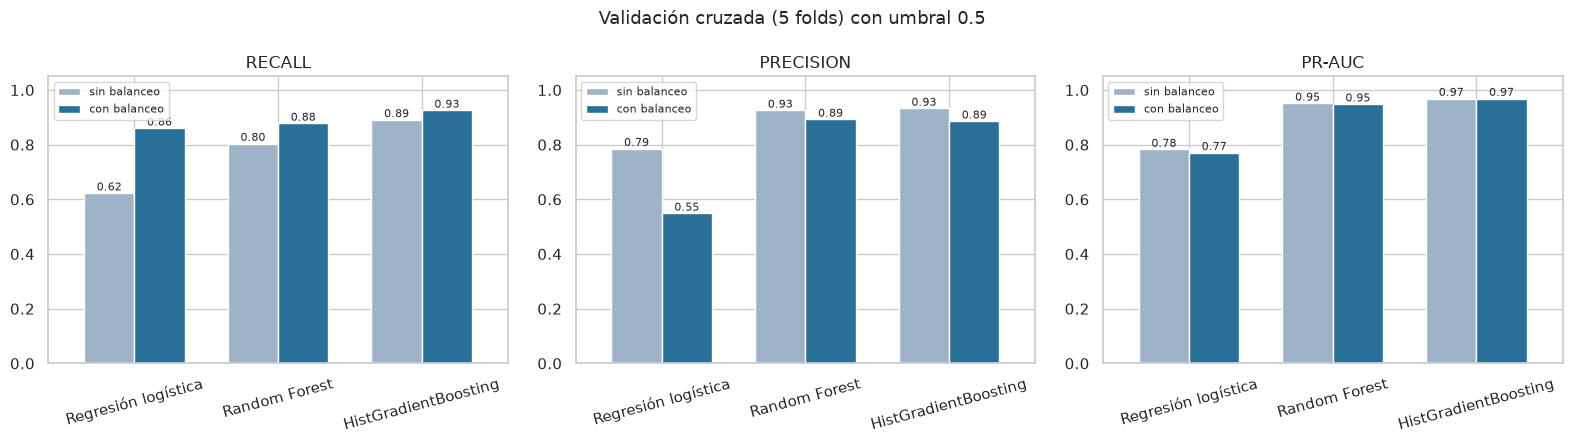

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metrica in zip(axes, ["recall", "precision", "pr_auc"]):
    datos = tabla_cv[metrica].unstack(0)
    datos.plot.bar(ax=ax, color=["#9fb3c8", "#2a6f97"], width=0.7)
    ax.set(title=metrica.upper().replace("_", "-"), ylim=(0, 1.05), xlabel="")
    ax.tick_params(axis="x", rotation=15)
    for cont in ax.containers:
        ax.bar_label(cont, fmt="%.2f", fontsize=8)
    ax.legend(title="", fontsize=8)
fig.suptitle("Validación cruzada (5 folds) con umbral 0.5", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURAS / "02_cv_comparacion.png", bbox_inches="tight")
plt.show()

**Lectura de los resultados.**

1. **La accuracy engaña, como se anticipó.** La regresión logística sin balanceo tiene 91.2% de accuracy pero solo detecta el 62.3% de los abandonos. Con balanceo sube el recall a 86.0% a costa de la precisión (55%): la mitad de los clientes que marca no se iban. Es el techo de un modelo lineal aquí: las relaciones no son lineales (vimos en el EDA que el riesgo "salta" a partir de 3 contactos o 3 meses inactivo).

2. **Los árboles superan por mucho a la logística.** Random Forest alcanza PR-AUC 0.95 y boosting **0.97**, frente a 0.77 de la logística. Confirma que el problema es no lineal y con interacciones.

3. **El balanceo ayuda sobre todo al recall.** En Random Forest sube de 80% a 88%; en boosting, de 89% a 93%. PR-AUC y ROC-AUC casi no cambian porque el ranking es el mismo: el peso de clases desplaza las probabilidades, no reordena a los clientes.

4. **HistGradientBoosting es el mejor en todas las métricas y el más estable** (desviación estándar entre folds ≈ 0.01). Es el candidato.

## 5. Elección del umbral de decisión

Un modelo devuelve una probabilidad. Convertirla en "llamar / no llamar" exige un **umbral**. El 0.5 por defecto no tiene ningún significado de negocio. Fijamos el umbral con una regla explícita:

> **El banco quiere detectar al menos el 90% de los abandonos.** Dentro de esa restricción, elegimos el umbral más alto posible (= menos clientes marcados = menos llamadas innecesarias).

Para hacerlo sin tocar el test, obtenemos **probabilidades fuera de muestra** sobre el train con `cross_val_predict`: cada cliente recibe la predicción de un modelo que no lo vio al entrenar.

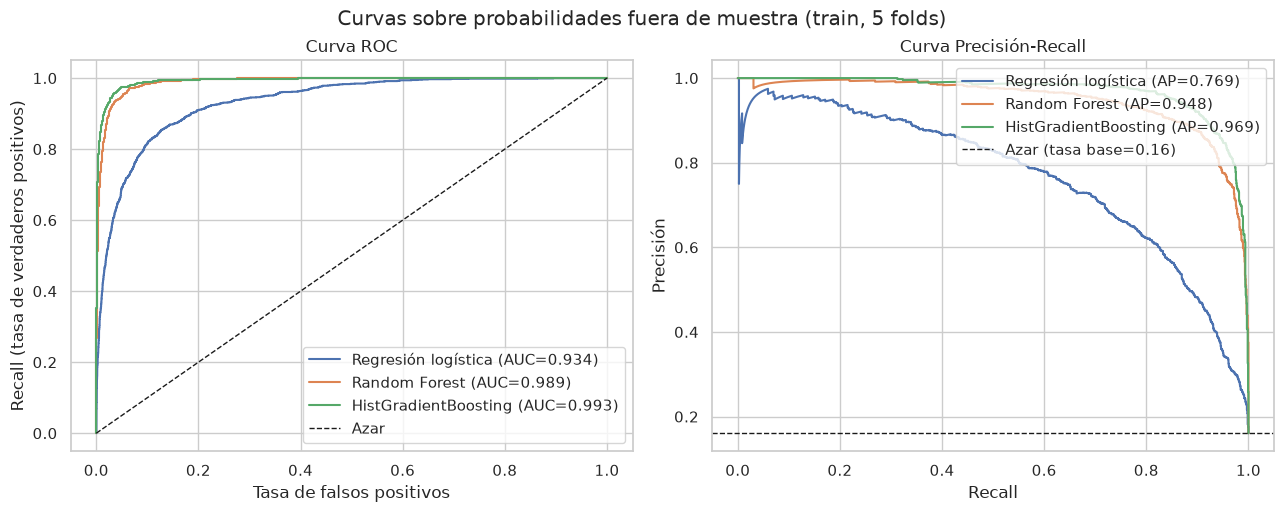

In [7]:
modelos = construir_modelos(balancear_clases=True)
probas_cv = {nombre: probabilidades_cv(pipe, X_train, y_train, n_folds=5) for nombre, pipe in modelos.items()}

fig = graficar_curvas(probas_cv, y_train, ruta_guardado=FIGURAS / "02_curvas_cv.png")
fig.suptitle("Curvas sobre probabilidades fuera de muestra (train, 5 folds)", y=1.02)
plt.show()

In [8]:
RECALL_OBJETIVO = 0.90
umbrales = {}
for nombre, proba in probas_cv.items():
    umbrales[nombre] = elegir_umbral_por_recall(y_train, proba, recall_minimo=RECALL_OBJETIVO)

resumen = pd.DataFrame(
    [{"modelo": n, **calcular_metricas(y_train, probas_cv[n], umbrales[n])} for n in modelos]
).set_index("modelo")
print(f"Métricas (CV) en el umbral que garantiza recall ≥ {RECALL_OBJETIVO:.0%}:")
resumen.round(3)

Métricas (CV) en el umbral que garantiza recall ≥ 90%:


,umbral,recall,precision,f1,roc_auc,pr_auc,n_marcados
modelo,,,,,,,
Regresión logística,0.391,0.9,0.482,0.628,0.934,0.769,2431
Random Forest,0.468,0.9,0.875,0.888,0.989,0.948,1339
HistGradientBoosting,0.674,0.9,0.921,0.910,0.993,0.969,1273


In [9]:
print("Trade-off recall / precisión para HistGradientBoosting según el umbral (CV):")
tabla_umbrales(y_train, probas_cv["HistGradientBoosting"]).round(3)

Trade-off recall / precisión para HistGradientBoosting según el umbral (CV):


,recall,precision,f1,roc_auc,pr_auc,n_marcados
umbral,,,,,,
0.1,0.979,0.738,0.842,0.993,0.969,1727
0.2,0.965,0.814,0.883,0.993,0.969,1545
0.3,0.950,0.850,0.897,0.993,0.969,1455
0.4,0.938,0.869,0.902,0.993,0.969,1405
0.5,0.925,0.885,0.905,0.993,0.969,1361
0.6,0.912,0.904,0.908,0.993,0.969,1314
0.7,0.894,0.925,0.909,0.993,0.969,1258
0.8,0.866,0.943,0.903,0.993,0.969,1196
0.9,0.823,0.962,0.887,0.993,0.969,1113


**Lectura.** Para capturar el 90% de los abandonos:

- La **regresión logística** tendría que marcar a 2,431 clientes de 8,101 (30%) con solo 48% de precisión: más de la mitad de las llamadas serían a clientes fieles.
- **Random Forest** marcaría a 1,339 con 87.5% de precisión.
- **HistGradientBoosting** marcaría a 1,273 con **92.1% de precisión** usando un umbral de **0.67**. Es decir, de cada 100 clientes contactados, 92 realmente iban a irse.

Elegimos **HistGradientBoosting con umbral 0.67**.

### 5.1 Análisis de sensibilidad: el umbral como decisión económica

El umbral "correcto" depende de cuánto vale un cliente frente a cuánto cuesta retenerlo. Para ilustrarlo, usamos **supuestos hipotéticos** (el dataset no trae costos): perder un cliente cuesta 1,000 unidades monetarias y cada contacto de retención cuesta 50. Con ese ratio 20:1 calculamos el costo total por umbral.

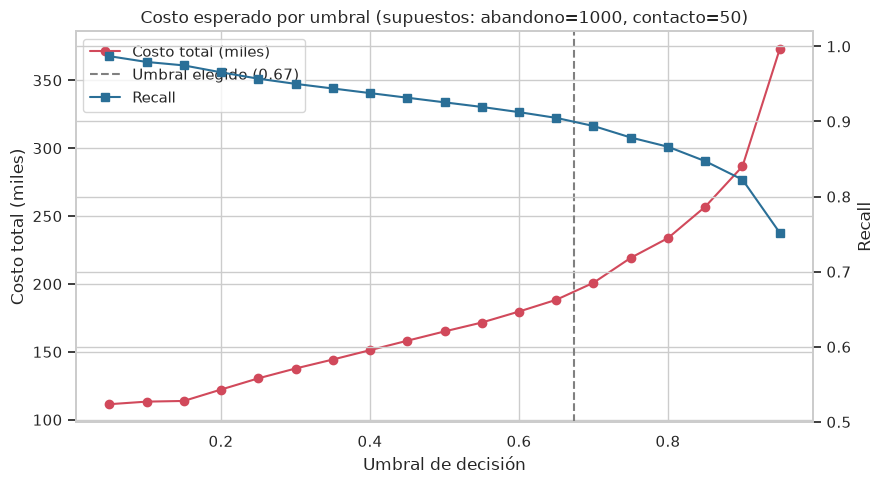

,recall,precision,n_marcados,costo_total
umbral,,,,
0.2,0.965,0.814,1545,122250.0
0.4,0.938,0.869,1405,151250.0
0.6,0.912,0.904,1314,179700.0
0.8,0.866,0.943,1196,233800.0


In [10]:
COSTO_ABANDONO = 1000  # supuesto: valor anual de un cliente perdido
COSTO_CONTACTO = 50    # supuesto: costo de una acción de retención

costos = tabla_costos(y_train, probas_cv["HistGradientBoosting"], COSTO_ABANDONO, COSTO_CONTACTO)

fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(costos.index, costos["costo_total"] / 1000, marker="o", color="#d1495b", label="Costo total (miles)")
ax1.set(xlabel="Umbral de decisión", ylabel="Costo total (miles)", title="Costo esperado por umbral (supuestos: abandono=1000, contacto=50)")
ax2 = ax1.twinx()
ax2.plot(costos.index, costos["recall"], marker="s", color="#2a6f97", label="Recall")
ax2.set(ylabel="Recall", ylim=(0.5, 1.02))
ax1.axvline(umbrales["HistGradientBoosting"], color="gray", ls="--", label=f"Umbral elegido ({umbrales['HistGradientBoosting']:.2f})")
lineas = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
etiquetas = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lineas, etiquetas, loc="upper left")
fig.tight_layout()
fig.savefig(FIGURAS / "02_costo_umbral.png", bbox_inches="tight")
plt.show()

costos.loc[[0.2, 0.4, 0.6, 0.8]].round(3)

**Lectura.** Con un ratio 20:1, el costo mínimo está en umbrales muy bajos (por debajo de 0.2): sale más barato llamar a algunos clientes fieles de más que dejar escapar abandonos. Nuestro umbral de 0.67 es **más conservador** que ese óptimo. Esto es intencional: la regla "recall ≥ 90%" es un compromiso claro y explicable para negocio, mientras que el análisis de costos depende de dos números que aquí son supuestos. Si el banco aporta costos reales, el umbral se recalcula con `tabla_costos` sin reentrenar nada.

La conclusión importante para un gerente: **el umbral no es un parámetro técnico, es una decisión de negocio**. El modelo ordena a los clientes por riesgo; hasta dónde llamar lo decide el presupuesto de retención.

## 6. Evaluación final sobre el conjunto de test

Entrenamos el modelo elegido con **todo** el train y lo evaluamos **una sola vez** en el test con el umbral fijado en CV. Los tres modelos se evalúan para completar la comparación, pero la decisión ya está tomada.

In [11]:
probas_test = {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    probas_test[nombre] = pipe.predict_proba(X_test)[:, 1]

tabla_test = pd.DataFrame(
    [{"modelo": n, **calcular_metricas(y_test, probas_test[n], umbrales[n])} for n in modelos]
).set_index("modelo")
print("Métricas en TEST con el umbral elegido en CV para cada modelo:")
tabla_test.round(3)

Métricas en TEST con el umbral elegido en CV para cada modelo:


,umbral,recall,precision,f1,roc_auc,pr_auc,n_marcados
modelo,,,,,,,
Regresión logística,0.391,0.877,0.494,0.632,0.935,0.761,577
Random Forest,0.468,0.865,0.857,0.861,0.988,0.950,328
HistGradientBoosting,0.674,0.889,0.932,0.910,0.992,0.965,310


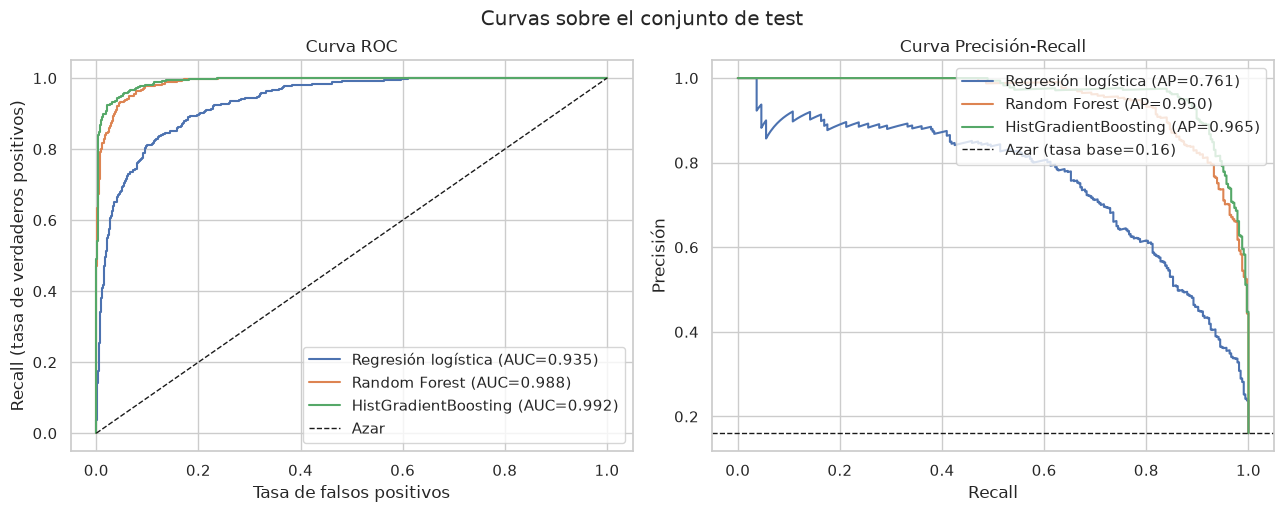

In [12]:
fig = graficar_curvas(probas_test, y_test, ruta_guardado=FIGURAS / "02_curvas_test.png")
fig.suptitle("Curvas sobre el conjunto de test", y=1.02)
plt.show()

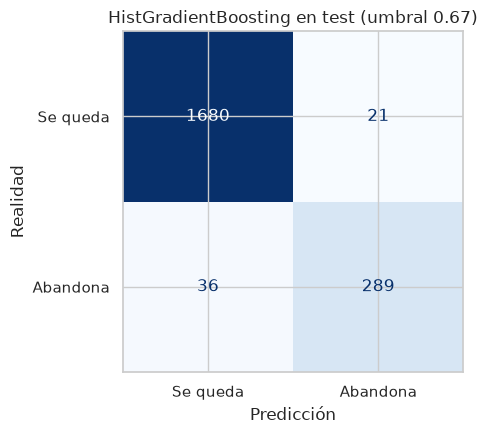

verdaderos_positivos (abandonos detectados)          289
falsos_negativos (abandonos NO detectados)            36
falsos_positivos (fieles marcados por error)          21
verdaderos_negativos (fieles bien clasificados)     1680

Árboles usados por el boosting (early stopping): 188


In [13]:
MODELO_FINAL = "HistGradientBoosting"
umbral_final = umbrales[MODELO_FINAL]
proba_final = probas_test[MODELO_FINAL]

graficar_matriz_confusion(y_test, proba_final, umbral_final,
                          titulo=f"{MODELO_FINAL} en test (umbral {umbral_final:.2f})",
                          ruta_guardado=FIGURAS / "02_matriz_confusion_test.png")
plt.show()

conteos = resumen_confusion(y_test, proba_final, umbral_final)
for k, v in conteos.items():
    print(f"{k:50s} {v:>5}")
print(f"\nÁrboles usados por el boosting (early stopping): {modelos[MODELO_FINAL].named_steps['modelo'].n_iter_}")

**Resultado final en test (HistGradientBoosting, umbral 0.67), sobre 2,026 clientes nunca vistos:**

| Métrica | Valor |
|---|---|
| Recall | **0.889** → detecta 289 de los 325 clientes que abandonaron |
| Precisión | **0.932** → de 310 clientes marcados, 289 realmente se fueron; solo 21 falsas alarmas |
| F1 | 0.910 |
| ROC-AUC | 0.992 |
| PR-AUC | 0.965 |

Los valores de test están muy cerca de los de validación cruzada (recall 0.90, precisión 0.921): el modelo **no está sobreajustado** y la estimación de CV era fiable.

En términos de negocio: con un presupuesto para contactar al **15% de la cartera**, el modelo permite llegar al **89% de los clientes que se iban**. Sin modelo, contactando al 15% al azar, se llegaría al 15%.

## 7. Guardar el modelo y los resultados

El notebook 03 usa el modelo entrenado para interpretarlo y generar el CSV para Tableau.

In [14]:
joblib.dump(modelos[MODELO_FINAL], OUTPUTS / "modelo_final.joblib")
joblib.dump(modelos["Regresión logística"], OUTPUTS / "modelo_logistica.joblib")

metricas_finales = {
    "modelo_final": MODELO_FINAL,
    "umbral": float(umbral_final),
    "recall_objetivo_cv": RECALL_OBJETIVO,
    "test": {k: (float(v) if isinstance(v, (float, np.floating)) else int(v)) for k, v in calcular_metricas(y_test, proba_final, umbral_final).items()},
    "test_confusion": conteos,
    "cv_con_balanceo": tabla_cv.loc["con balanceo"].round(4).to_dict(orient="index"),
    "cv_sin_balanceo": tabla_cv.loc["sin balanceo"].round(4).to_dict(orient="index"),
    "umbrales_por_modelo": {k: float(v) for k, v in umbrales.items()},
}
with open(OUTPUTS / "metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas_finales, f, indent=2, ensure_ascii=False)

# Probabilidades fuera de muestra del train: se usan en el notebook 03 para que
# TODOS los clientes del CSV final tengan una probabilidad honesta (no de memoria)
pd.DataFrame({"CLIENTNUM": train["CLIENTNUM"], "probabilidad_abandono": probas_cv[MODELO_FINAL]}).to_csv(
    OUTPUTS / "probas_cv_train.csv", index=False)
pd.DataFrame({"CLIENTNUM": test["CLIENTNUM"], "probabilidad_abandono": proba_final}).to_csv(
    OUTPUTS / "probas_test.csv", index=False)

print("Guardado en outputs/: modelo_final.joblib, modelo_logistica.joblib, metricas.json, probas_cv_train.csv, probas_test.csv")

Guardado en outputs/: modelo_final.joblib, modelo_logistica.joblib, metricas.json, probas_cv_train.csv, probas_test.csv


## 8. Resumen de decisiones de modelado

| Decisión | Alternativa descartada | Motivo |
|---|---|---|
| Partición estratificada 80/20 + CV 5-fold sobre train | Una sola partición | Con 16% de positivos, una sola partición da métricas inestables; la CV promedia 5 estimaciones |
| Preprocesamiento dentro del Pipeline | Escalar antes de la CV | Evita fuga de información entre folds |
| `class_weight="balanced"` | SMOTE / undersampling | Mismo efecto sin inventar ni descartar datos; más simple de explicar y de poner en producción |
| PR-AUC como métrica de selección | ROC-AUC / accuracy | Centrada en la clase minoritaria; accuracy engaña con desbalance |
| Umbral por recall objetivo (90%) | Umbral 0.5 | 0.5 no significa nada para negocio; la regla de recall es explicable y auditable |
| HistGradientBoosting | Random Forest | Mejor en todas las métricas (+0.02 PR-AUC), más estable, y entrena en segundos |
| Early stopping en boosting | Número fijo de árboles | Para automáticamente cuando deja de mejorar (usó ~190 de 500), reduce sobreajuste |